# What Makes an Airbnb Listing Sell Out?

Analysis of 10,000 synthetic short-term rental listings across 12 cities.  
**Goals:**
- Explore feature distributions and relationships
- Classify high-demand listings (top 25% occupancy)
- Predict annual revenue (regression)

**Dataset:** [Kaggle — What Makes an Airbnb Listing Sell Out?](https://www.kaggle.com/datasets/vedauv/what-makes-an-airbnb-listing-sell-out-10k-stays)

## 1. Setup & Data Loading

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor,
    GradientBoostingClassifier, GradientBoostingRegressor,
)
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    mean_squared_error, mean_absolute_error, r2_score
)
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 25)

SEED = 42

In [43]:
df = pd.read_csv("data/stay_listings.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (10000, 21)


,listing_id,city,property_type,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,host_response_rate,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
0,L00001,Mexico City,Entire home,2,1.5,5,7.1,52.0,17.0,1,96.0,6.9,27,23,0,30,4.59,3,61.3,11500.0,0
1,L00002,Paris,Entire home,1,1.0,3,4.6,147.0,52.0,0,94.0,1.4,13,20,1,7,4.61,7,23.7,11300.0,0
2,L00003,New York,Entire home,2,2.0,5,1.6,131.0,36.0,0,95.0,5.1,18,35,0,30,4.64,6,45.8,21700.0,0
3,L00004,Tokyo,Entire home,2,1.5,5,5.7,164.0,68.0,0,84.0,3.6,36,43,0,2,4.71,20,42.6,25300.0,0
4,L00005,Berlin,Entire home,3,2.0,8,4.6,321.0,32.0,1,100.0,5.6,27,48,1,5,4.98,28,65.1,74500.0,0


In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           10000 non-null  str    
 1   city                 10000 non-null  str    
 2   property_type        10000 non-null  str    
 3   bedrooms             10000 non-null  int64  
 4   bathrooms            10000 non-null  float64
 5   guest_capacity       10000 non-null  int64  
 6   distance_center_km   10000 non-null  float64
 7   price_per_night_usd  10000 non-null  float64
 8   cleaning_fee_usd     10000 non-null  float64
 9   superhost            10000 non-null  int64  
 10  host_response_rate   10000 non-null  float64
 11  host_years           10000 non-null  float64
 12  photo_count          10000 non-null  int64  
 13  amenities_count      10000 non-null  int64  
 14  instant_book         10000 non-null  int64  
 15  min_nights           10000 non-null  int64  
 16

In [45]:
df.describe()

,bedrooms,bathrooms,guest_capacity,distance_center_km,price_per_night_usd,cleaning_fee_usd,superhost,host_response_rate,host_years,photo_count,amenities_count,instant_book,min_nights,review_score,reviews_count,occupancy_rate_pct,annual_revenue_usd,high_demand
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.0000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.406600,1.563800,4.327500,4.109520,91.666300,27.487600,0.361700,91.728000,3.175140,22.053600,28.208400,0.4460,5.056100,4.599185,49.210400,52.994650,16125.830000,0.250400
std,0.936143,0.499354,1.942375,3.730051,45.596351,18.061541,0.480517,5.791474,2.822191,9.268696,9.509943,0.4971,8.383781,0.188447,43.691224,19.478673,9699.187762,0.433265
min,0.000000,0.500000,1.000000,0.200000,18.000000,2.000000,0.000000,66.000000,0.200000,3.000000,3.000000,0.0000,1.000000,3.880000,0.000000,3.000000,400.000000,0.000000
25%,1.000000,1.000000,3.000000,1.800000,59.000000,15.000000,0.000000,88.000000,1.100000,16.000000,22.000000,0.0000,1.000000,4.470000,18.000000,39.600000,9500.000000,0.000000
50%,1.000000,1.500000,4.000000,3.000000,82.000000,23.000000,0.000000,92.000000,2.300000,22.000000,28.000000,0.0000,2.000000,4.600000,38.000000,52.900000,13950.000000,0.000000
75%,2.000000,2.000000,5.000000,5.100000,114.000000,36.000000,1.000000,96.000000,4.400000,28.000000,35.000000,1.0000,3.000000,4.730000,67.000000,66.600000,20500.000000,1.000000
max,4.000000,3.500000,10.000000,30.000000,414.000000,164.000000,1.000000,100.000000,14.000000,55.000000,65.000000,1.0000,30.000000,5.000000,417.000000,98.000000,85500.000000,1.000000


In [46]:
df.isnull().sum().sum()

np.int64(0)

## 2. Exploratory Data Analysis

### 2.1 Target Distribution

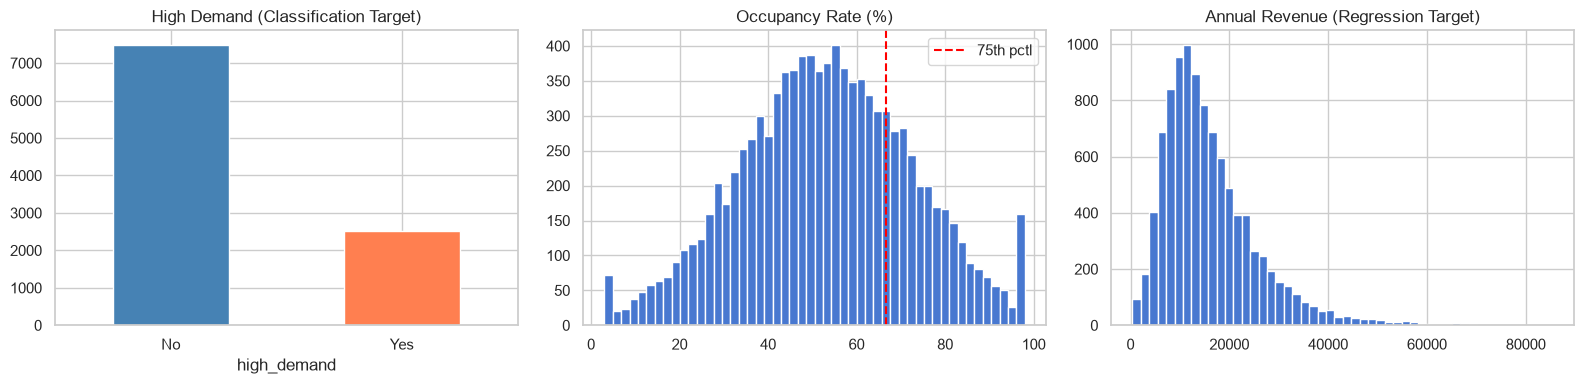

high_demand positive rate: 25.0%
Revenue skewness: 1.65


In [47]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df["high_demand"].value_counts().plot.bar(ax=axes[0], color=["steelblue", "coral"])
axes[0].set_title("High Demand (Classification Target)")
axes[0].set_xticklabels(["No", "Yes"], rotation=0)

axes[1].hist(df["occupancy_rate_pct"], bins=50, edgecolor="white")
axes[1].axvline(df["occupancy_rate_pct"].quantile(0.75), color="red", linestyle="--", label="75th pctl")
axes[1].set_title("Occupancy Rate (%)")
axes[1].legend()

axes[2].hist(df["annual_revenue_usd"], bins=50, edgecolor="white")
axes[2].set_title("Annual Revenue (Regression Target)")

plt.tight_layout()
plt.show()

print(f"high_demand positive rate: {df['high_demand'].mean():.1%}")
print(f"Revenue skewness: {df['annual_revenue_usd'].skew():.2f}")

### 2.2 Feature Distributions

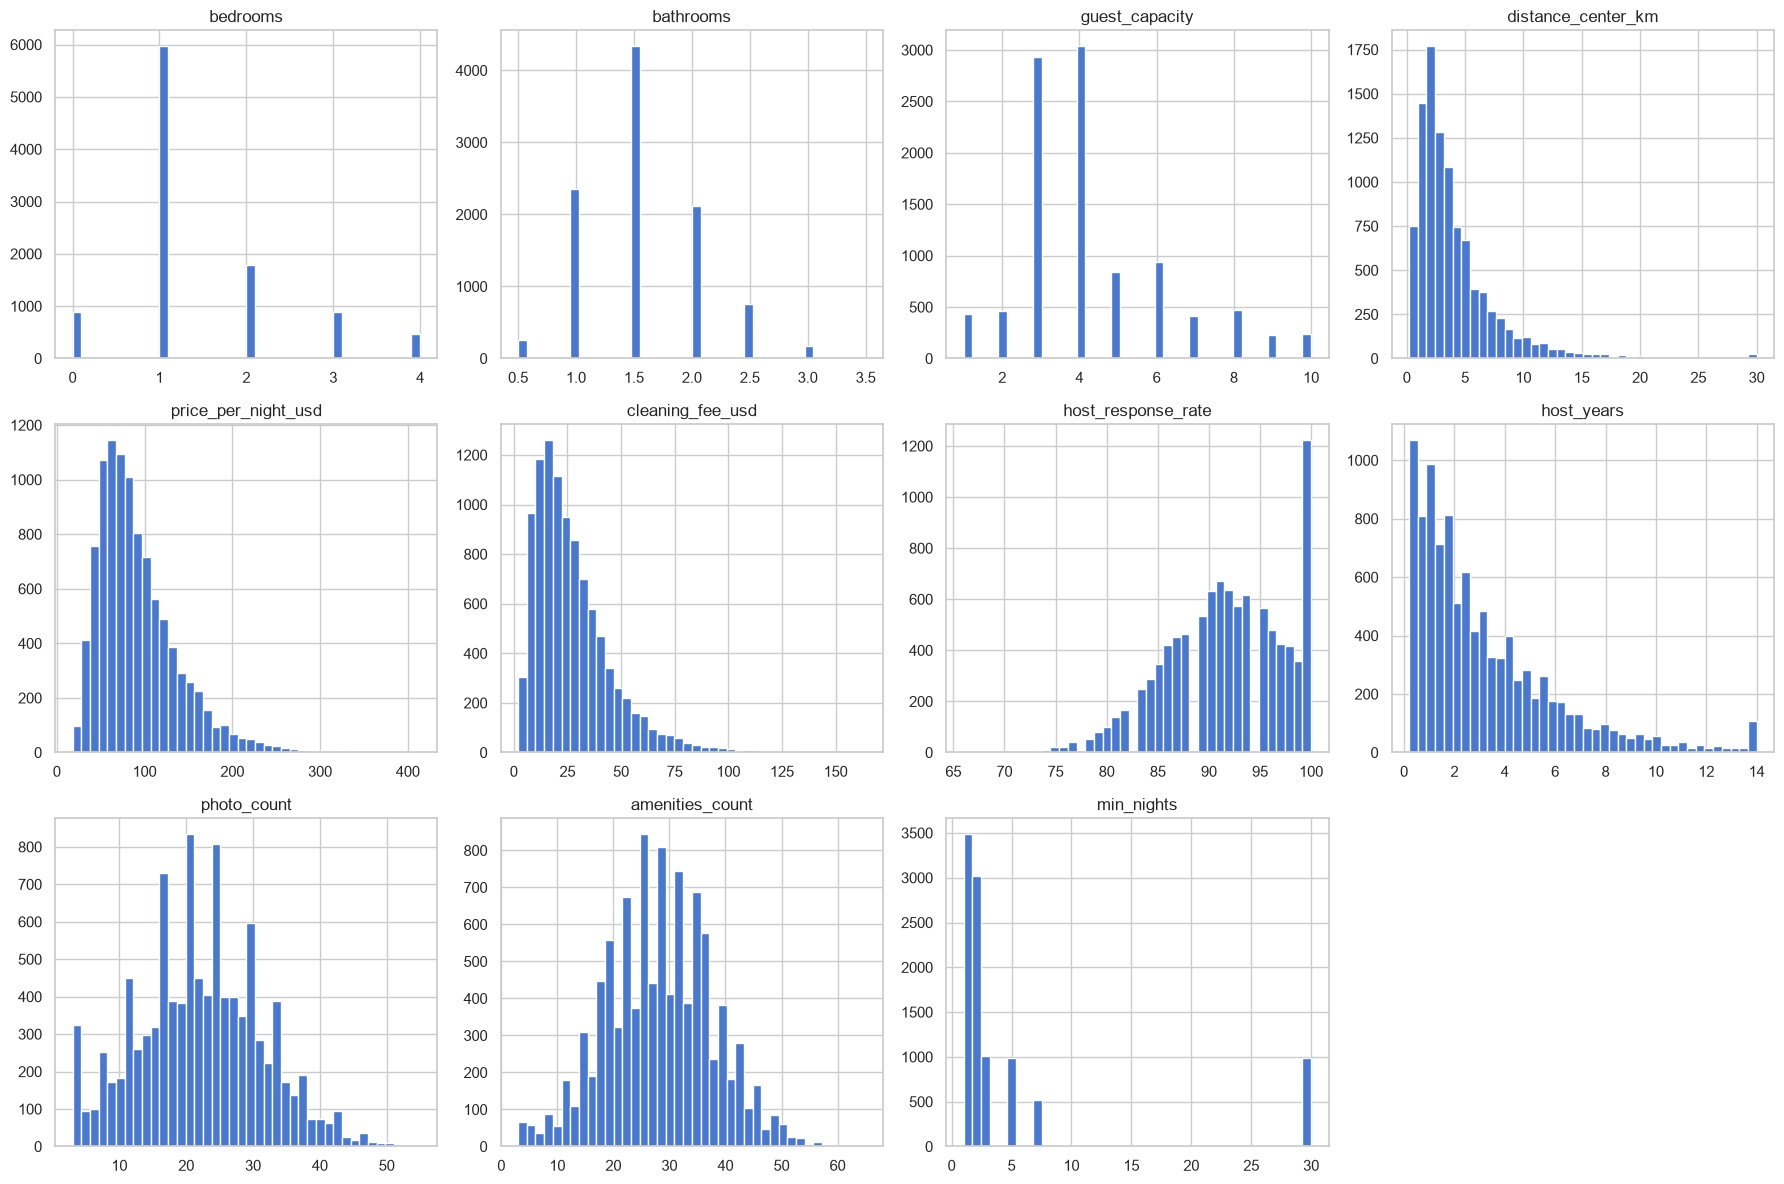

In [48]:
numeric_features = [
    "bedrooms", "bathrooms", "guest_capacity", "distance_center_km",
    "price_per_night_usd", "cleaning_fee_usd", "host_response_rate",
    "host_years", "photo_count", "amenities_count", "min_nights"
]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for i, col in enumerate(numeric_features):
    ax = axes[i // 4, i % 4]
    df[col].hist(bins=40, ax=ax, edgecolor="white")
    ax.set_title(col)
axes[2, 3].axis("off")
plt.tight_layout()
plt.show()

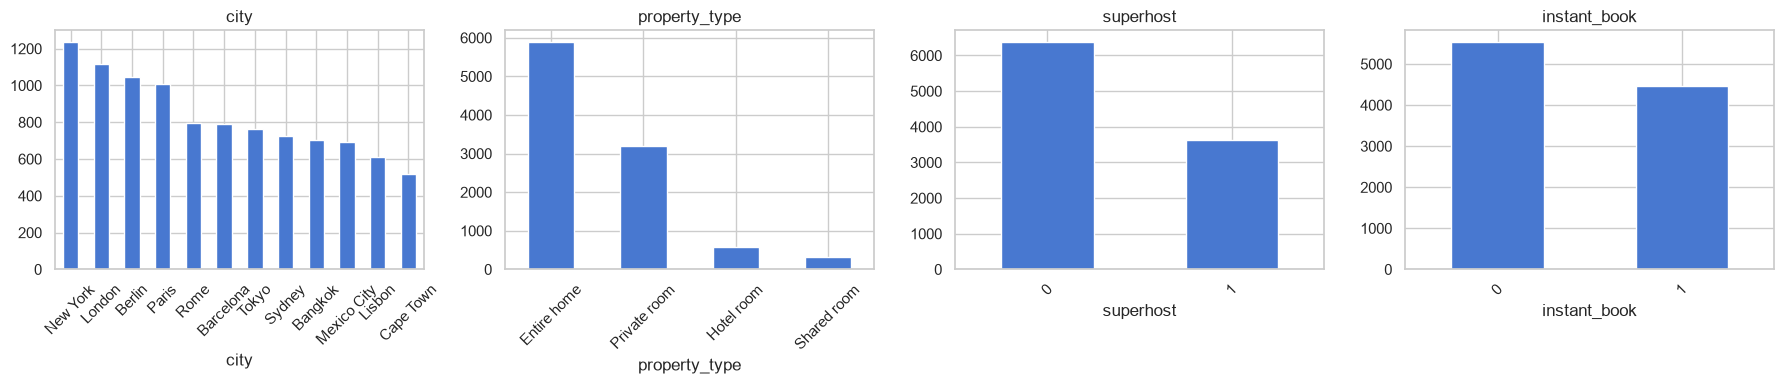

In [49]:
cat_features = ["city", "property_type", "superhost", "instant_book"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, col in enumerate(cat_features):
    df[col].value_counts().plot.bar(ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 2.3 Correlation Heatmap

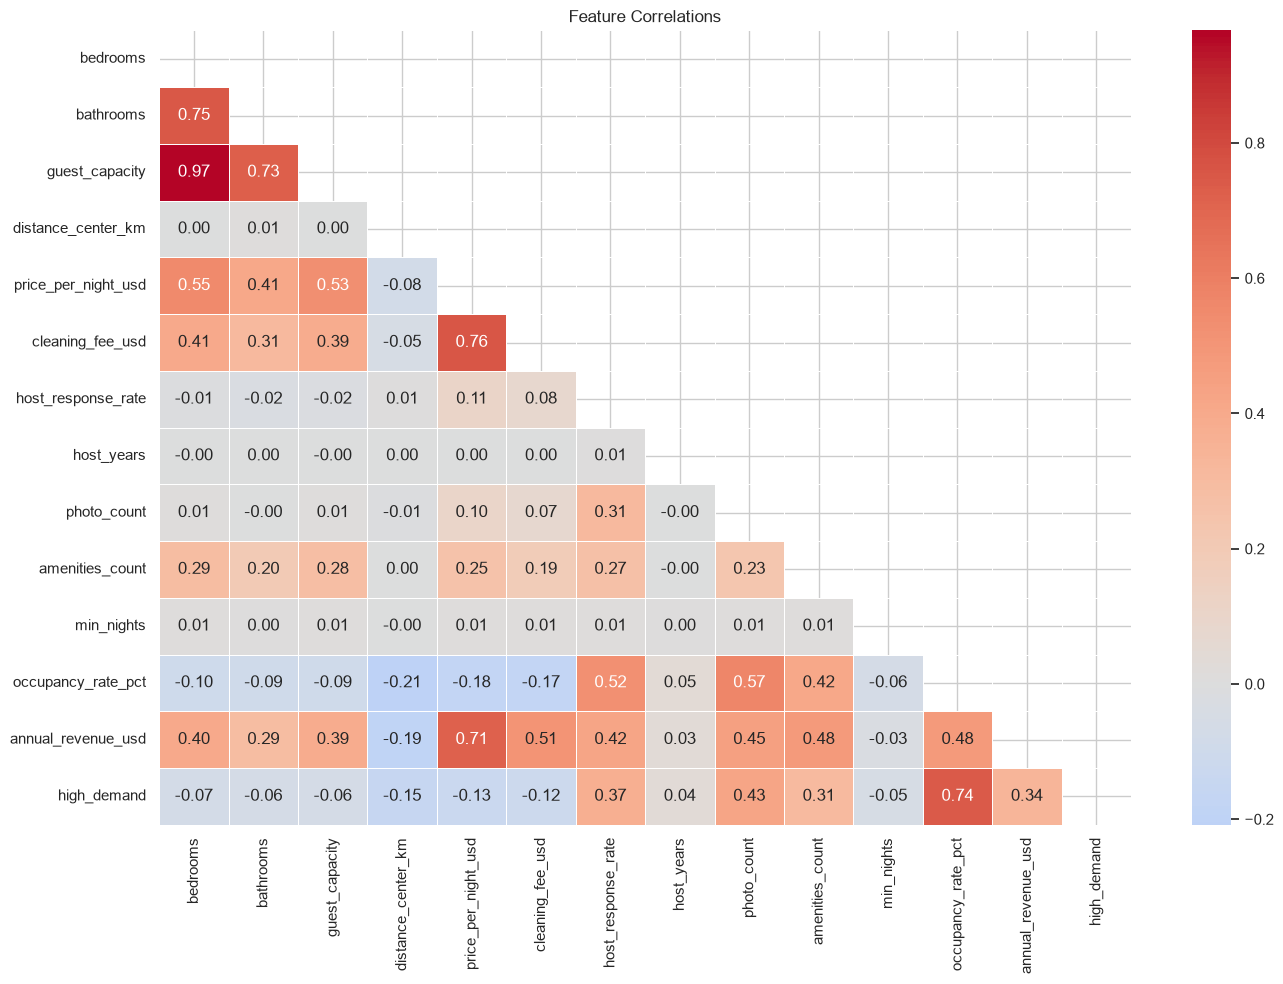

In [50]:
corr_cols = numeric_features + ["occupancy_rate_pct", "annual_revenue_usd", "high_demand"]
corr = df[corr_cols].corr()

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Feature Correlations")
plt.tight_layout()
plt.show()

### 2.4 City-Level Analysis

In [51]:
city_stats = df.groupby("city").agg(
    listings=("listing_id", "count"),
    avg_price=("price_per_night_usd", "mean"),
    avg_occupancy=("occupancy_rate_pct", "mean"),
    avg_revenue=("annual_revenue_usd", "mean"),
    high_demand_rate=("high_demand", "mean"),
    superhost_rate=("superhost", "mean"),
).round(1)

city_stats.sort_values("avg_revenue", ascending=False)

,listings,avg_price,avg_occupancy,avg_revenue,high_demand_rate,superhost_rate
city,,,,,,
London,1114,108.3,50.1,18352.7,0.2,0.4
New York,1237,112.5,47.9,17984.3,0.2,0.4
Paris,1009,105.4,49.4,17397.1,0.2,0.4
Sydney,723,98.9,51.9,17271.6,0.2,0.4
Tokyo,763,95.8,50.9,16477.7,0.2,0.4
Barcelona,788,91.4,52.6,16224.9,0.3,0.3
Lisbon,612,85.8,55.1,16042.8,0.3,0.4
Rome,794,90.2,53.0,16032.2,0.2,0.3
Berlin,1047,85.1,55.0,15655.4,0.3,0.4


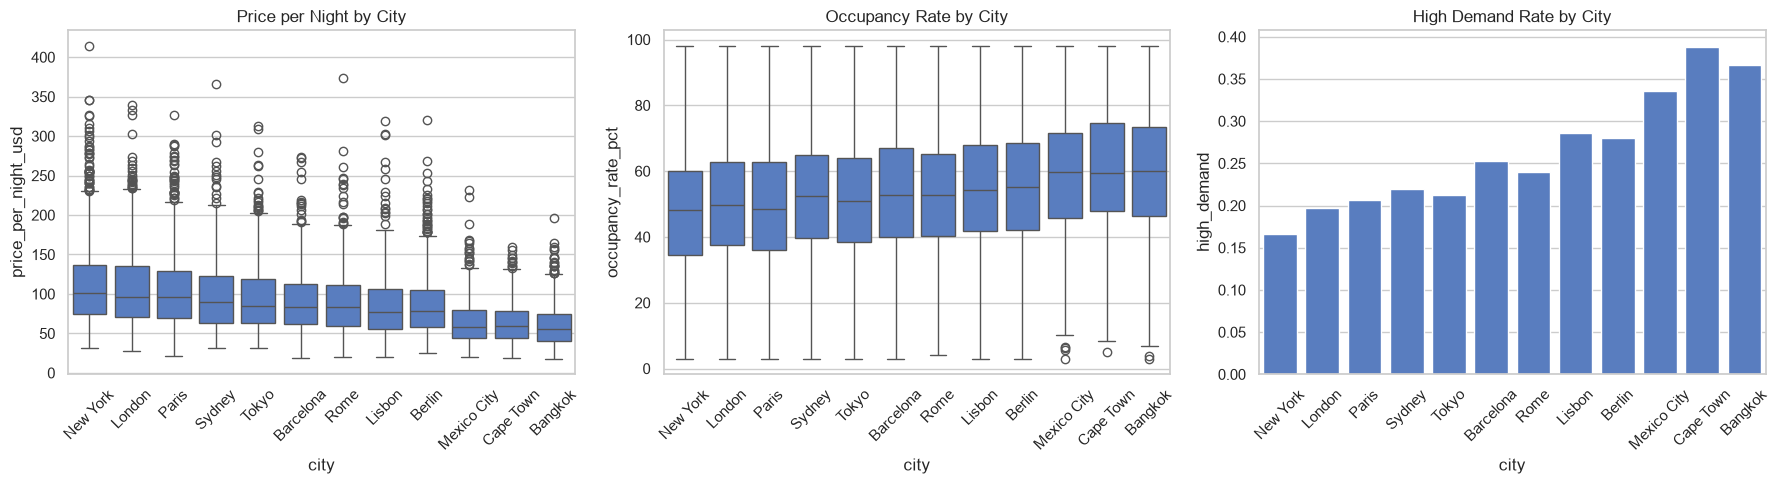

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

city_order = city_stats.sort_values("avg_price", ascending=False).index

sns.boxplot(data=df, x="city", y="price_per_night_usd", order=city_order, ax=axes[0])
axes[0].set_title("Price per Night by City")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=df, x="city", y="occupancy_rate_pct", order=city_order, ax=axes[1])
axes[1].set_title("Occupancy Rate by City")
axes[1].tick_params(axis="x", rotation=45)

sns.barplot(data=df, x="city", y="high_demand", order=city_order, ax=axes[2], errorbar=None)
axes[2].set_title("High Demand Rate by City")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### 2.5 Key Feature Relationships

/var/folders/mx/_lvtfb810wsffrg11sysxvsm0000gp/T/ipykernel_82361/922328223.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1, 0].set_xticklabels(["No", "Yes"])


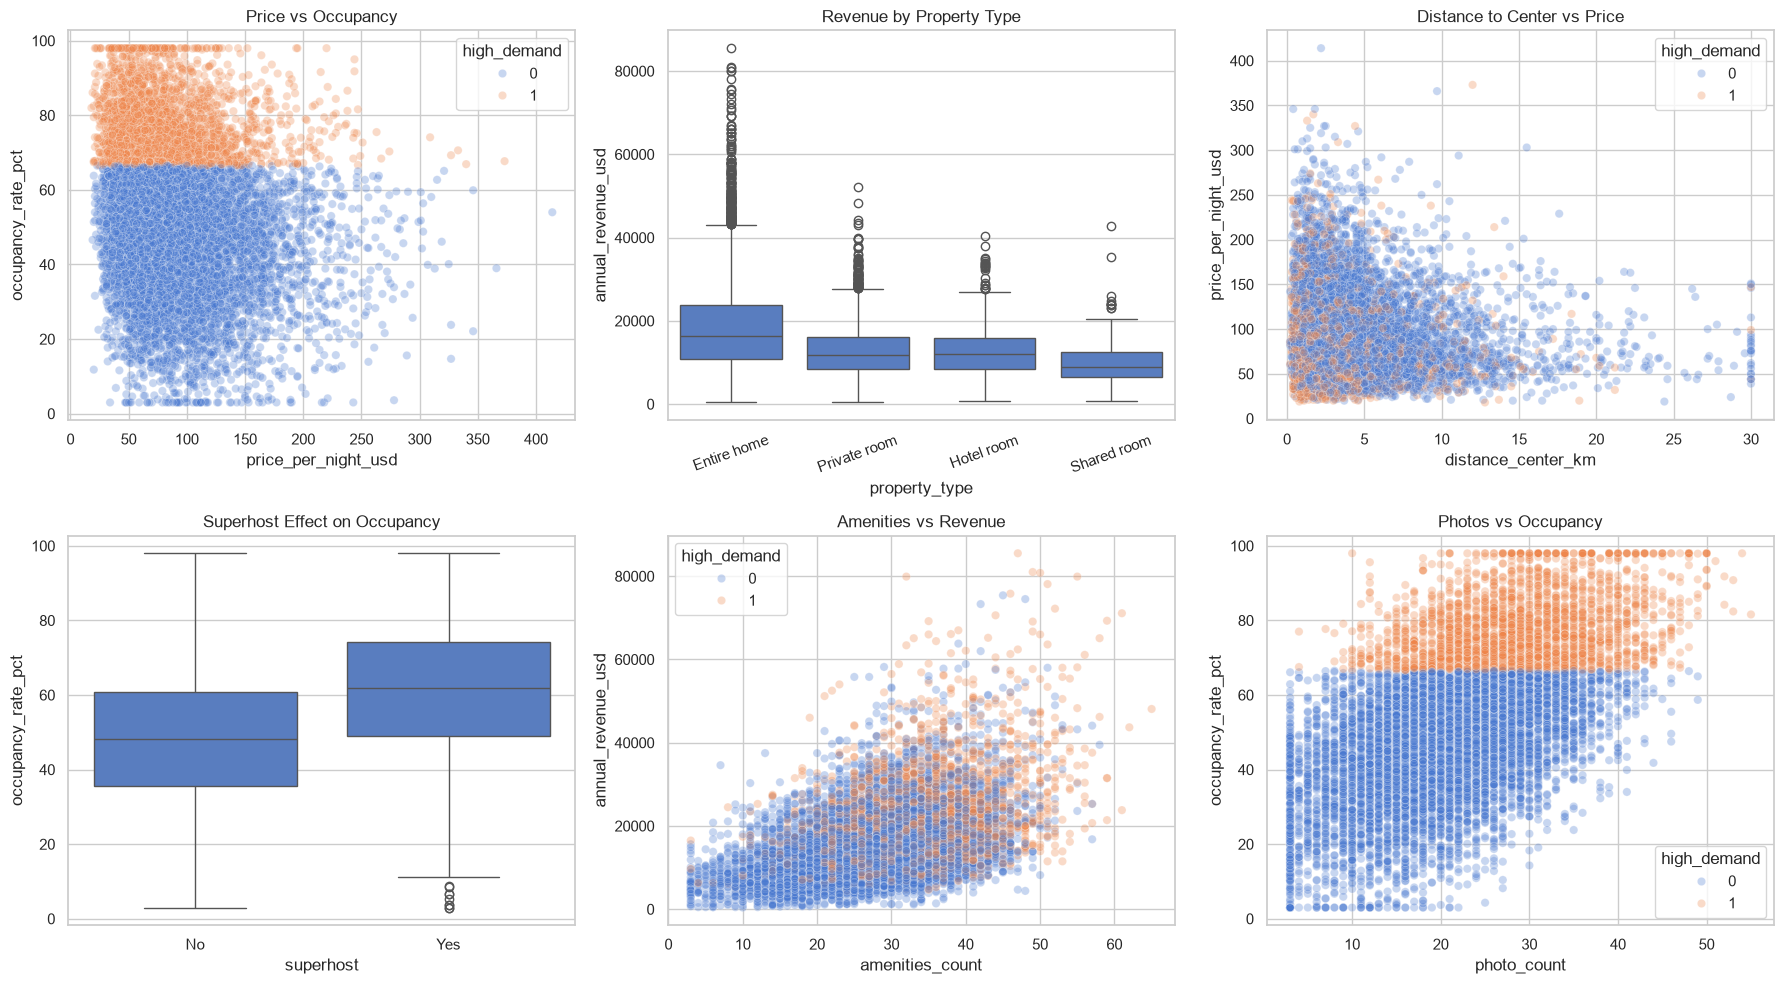

In [53]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.scatterplot(data=df, x="price_per_night_usd", y="occupancy_rate_pct", hue="high_demand",
                alpha=0.3, ax=axes[0, 0])
axes[0, 0].set_title("Price vs Occupancy")

sns.boxplot(data=df, x="property_type", y="annual_revenue_usd", ax=axes[0, 1])
axes[0, 1].set_title("Revenue by Property Type")
axes[0, 1].tick_params(axis="x", rotation=20)

sns.scatterplot(data=df, x="distance_center_km", y="price_per_night_usd", hue="high_demand",
                alpha=0.3, ax=axes[0, 2])
axes[0, 2].set_title("Distance to Center vs Price")

sns.boxplot(data=df, x="superhost", y="occupancy_rate_pct", ax=axes[1, 0])
axes[1, 0].set_title("Superhost Effect on Occupancy")
axes[1, 0].set_xticklabels(["No", "Yes"])

sns.scatterplot(data=df, x="amenities_count", y="annual_revenue_usd", hue="high_demand",
                alpha=0.3, ax=axes[1, 1])
axes[1, 1].set_title("Amenities vs Revenue")

sns.scatterplot(data=df, x="photo_count", y="occupancy_rate_pct", hue="high_demand",
                alpha=0.3, ax=axes[1, 2])
axes[1, 2].set_title("Photos vs Occupancy")

plt.tight_layout()
plt.show()

## 3. Feature Engineering & Preprocessing

In [54]:
outcome_cols = ["review_score", "reviews_count", "occupancy_rate_pct", "annual_revenue_usd", "high_demand"]
drop_cols = ["listing_id"] + outcome_cols

feature_cols = [c for c in df.columns if c not in drop_cols]
print(f"Features ({len(feature_cols)}): {feature_cols}")

Features (15): ['city', 'property_type', 'bedrooms', 'bathrooms', 'guest_capacity', 'distance_center_km', 'price_per_night_usd', 'cleaning_fee_usd', 'superhost', 'host_response_rate', 'host_years', 'photo_count', 'amenities_count', 'instant_book', 'min_nights']


In [55]:
df["total_cost"] = df["price_per_night_usd"] + df["cleaning_fee_usd"] / df["min_nights"].clip(lower=1)
df["price_per_guest"] = df["price_per_night_usd"] / df["guest_capacity"].clip(lower=1)
df["quality_score"] = df["photo_count"] + df["amenities_count"]

engineered_features = ["total_cost", "price_per_guest", "quality_score"]
feature_cols = feature_cols + engineered_features
print(f"Features after engineering ({len(feature_cols)}): {feature_cols}")

Features after engineering (18): ['city', 'property_type', 'bedrooms', 'bathrooms', 'guest_capacity', 'distance_center_km', 'price_per_night_usd', 'cleaning_fee_usd', 'superhost', 'host_response_rate', 'host_years', 'photo_count', 'amenities_count', 'instant_book', 'min_nights', 'total_cost', 'price_per_guest', 'quality_score']


### 3.1 Multicollinearity Analysis

Check which features carry redundant information. Tree-based models are robust to collinearity (it doesn't hurt accuracy), but it inflates feature importance scores and can destabilize linear models even with regularization.

In [56]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

num_feature_cols = [c for c in feature_cols if c not in ["city", "property_type"]]
X_vif = df[num_feature_cols].copy()
X_vif = (X_vif - X_vif.mean()) / X_vif.std()

vif = pd.DataFrame({
    "Feature": num_feature_cols,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
}).sort_values("VIF", ascending=False).round(1)

print("Variance Inflation Factors (VIF > 5 = concerning, > 10 = severe):\n")
print(vif.to_string(index=False))

high_vif = vif[vif["VIF"] > 5]["Feature"].tolist()
if high_vif:
    print(f"\n⚠ High VIF features: {high_vif}")
else:
    print("\n✓ No features with VIF > 5 — collinearity is not a concern.")

/var/folders/mx/_lvtfb810wsffrg11sysxvsm0000gp/T/ipykernel_82361/283894994.py:9: UserWarning: The design matrix is poorly conditioned (condition number=2.38e+15). VIF calculations may be numerically unstable.
  "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
/Users/christian.chua/anaconda3/envs/airbnb/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/christian.chua/anaconda3/envs/airbnb/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/christian.chua/anaconda3/envs/airbnb/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-

Variance Inflation Factors (VIF > 5 = concerning, > 10 = severe):

            Feature          VIF
        photo_count 1.000800e+15
    amenities_count 1.000800e+15
      quality_score 1.000800e+15
         total_cost 3.090000e+01
price_per_night_usd 2.630000e+01
     guest_capacity 1.860000e+01
           bedrooms 1.720000e+01
   cleaning_fee_usd 3.400000e+00
    price_per_guest 2.900000e+00
          bathrooms 2.300000e+00
         min_nights 1.400000e+00
 host_response_rate 1.200000e+00
          superhost 1.100000e+00
 distance_center_km 1.000000e+00
       instant_book 1.000000e+00
         host_years 1.000000e+00

⚠ High VIF features: ['photo_count', 'amenities_count', 'quality_score', 'total_cost', 'price_per_night_usd', 'guest_capacity', 'bedrooms']


/Users/christian.chua/anaconda3/envs/airbnb/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/christian.chua/anaconda3/envs/airbnb/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


In [57]:
pair_corr = df[num_feature_cols].corr().abs()
diag_vals = pair_corr.to_numpy(copy=True)
np.fill_diagonal(diag_vals, 0)
pair_corr = pd.DataFrame(diag_vals, index=pair_corr.index, columns=pair_corr.columns)

high_pairs = []
for i in range(len(pair_corr)):
    for j in range(i + 1, len(pair_corr)):
        r = pair_corr.iloc[i, j]
        if r > 0.6:
            high_pairs.append((pair_corr.index[i], pair_corr.columns[j], round(r, 3)))

high_pairs_df = pd.DataFrame(high_pairs, columns=["Feature A", "Feature B", "|r|"]).sort_values("|r|", ascending=False)
print("Feature pairs with |correlation| > 0.6:\n")
if len(high_pairs_df):
    print(high_pairs_df.to_string(index=False))
    print(f"\nNote: Tree-based models (XGBoost, LightGBM, RF) handle collinearity natively —")
    print("they split on whichever correlated feature is most useful at each node.")
    print("Dropping collinear features would only help Logistic Regression / Ridge.")
else:
    print("None found — no strong collinearity among numeric features.")

Feature pairs with |correlation| > 0.6:

          Feature A        Feature B   |r|
price_per_night_usd       total_cost 0.970
           bedrooms   guest_capacity 0.966
   cleaning_fee_usd       total_cost 0.815
    amenities_count    quality_score 0.790
        photo_count    quality_score 0.777
price_per_night_usd cleaning_fee_usd 0.760
           bedrooms        bathrooms 0.751
          bathrooms   guest_capacity 0.725

Note: Tree-based models (XGBoost, LightGBM, RF) handle collinearity natively —
they split on whichever correlated feature is most useful at each node.
Dropping collinear features would only help Logistic Regression / Ridge.


### 3.2 Interaction Screening

Systematically test candidate interaction features. For each pair, we measure the AUC lift (classification) when adding that single interaction to a lightweight XGBoost model. Only interactions that improve over the base feature set are worth adding.

In [58]:
from itertools import combinations

candidate_interactions = [
    ("price_per_night_usd", "amenities_count"),
    ("price_per_night_usd", "guest_capacity"),
    ("price_per_night_usd", "distance_center_km"),
    ("superhost", "host_response_rate"),
    ("superhost", "amenities_count"),
    ("superhost", "price_per_night_usd"),
    ("amenities_count", "photo_count"),
    ("bedrooms", "bathrooms"),
    ("bedrooms", "price_per_night_usd"),
    ("guest_capacity", "amenities_count"),
    ("distance_center_km", "amenities_count"),
    ("host_years", "host_response_rate"),
    ("cleaning_fee_usd", "price_per_night_usd"),
    ("min_nights", "price_per_night_usd"),
]

X_screen = df[feature_cols].copy()
y_screen = df["high_demand"]

screen_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
screen_prep = ColumnTransformer([
    ("num", StandardScaler(), num_feature_cols),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), ["city", "property_type"]),
])

base_pipe = Pipeline([
    ("prep", screen_prep),
    ("clf", XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1,
                          random_state=SEED, eval_metric="logloss", n_jobs=-1))
])
base_auc = cross_val_score(base_pipe, X_screen, y_screen, cv=screen_cv, scoring="roc_auc").mean()

results = []
for a, b in candidate_interactions:
    col_name = f"{a} × {b}"
    X_tmp = X_screen.copy()
    X_tmp[col_name] = df[a] * df[b]
    tmp_num = num_feature_cols + [col_name]
    tmp_prep = ColumnTransformer([
        ("num", StandardScaler(), tmp_num),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), ["city", "property_type"]),
    ])
    tmp_pipe = Pipeline([
        ("prep", tmp_prep),
        ("clf", XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1,
                              random_state=SEED, eval_metric="logloss", n_jobs=-1))
    ])
    auc = cross_val_score(tmp_pipe, X_tmp, y_screen, cv=screen_cv, scoring="roc_auc").mean()
    results.append({"Interaction": col_name, "CV AUC": round(auc, 5), "Lift": round(auc - base_auc, 5)})

interaction_df = pd.DataFrame(results).sort_values("Lift", ascending=False)
print(f"Base model CV AUC (no interactions): {base_auc:.5f}\n")
print(interaction_df.to_string(index=False))

beneficial = interaction_df[interaction_df["Lift"] > 0.001]
if len(beneficial):
    print(f"\n✓ {len(beneficial)} interactions with meaningful lift (> +0.001 AUC):")
    for _, row in beneficial.iterrows():
        print(f"  {row['Interaction']:45s} +{row['Lift']:.5f}")
else:
    print("\n→ No interactions produced meaningful lift — the base features already")
    print("  capture the signal. Tree models discover interactions internally via splits.")

Base model CV AUC (no interactions): 0.92832

                             Interaction  CV AUC     Lift
price_per_night_usd × distance_center_km 0.92950  0.00118
    distance_center_km × amenities_count 0.92842  0.00011
        min_nights × price_per_night_usd 0.92842  0.00011
  cleaning_fee_usd × price_per_night_usd 0.92839  0.00007
          bedrooms × price_per_night_usd 0.92831 -0.00000
           amenities_count × photo_count 0.92831 -0.00001
             superhost × amenities_count 0.92823 -0.00009
         superhost × price_per_night_usd 0.92815 -0.00016
         host_years × host_response_rate 0.92811 -0.00020
          superhost × host_response_rate 0.92806 -0.00026
   price_per_night_usd × amenities_count 0.92798 -0.00033
                    bedrooms × bathrooms 0.92792 -0.00039
    price_per_night_usd × guest_capacity 0.92788 -0.00044
        guest_capacity × amenities_count 0.92784 -0.00047

✓ 1 interactions with meaningful lift (> +0.001 AUC):
  price_per_night_usd × dista

In [59]:
cat_cols = ["city", "property_type"]
num_cols = [c for c in feature_cols if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
])

## 4. Classification — Predicting High Demand

In [60]:
X = df[feature_cols]
y_cls = df["high_demand"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_cls, test_size=0.2, random_state=SEED, stratify=y_cls
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train positive rate: {y_train.mean():.1%}")

Train: (8000, 18), Test: (2000, 18)
Train positive rate: 25.0%


### 4.1 Logistic Regression (Baseline)

In [61]:
lr_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
lr_scores = cross_val_score(lr_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"Logistic Regression CV AUC: {lr_scores.mean():.4f} ± {lr_scores.std():.4f}")

lr_pipe.fit(X_train, y_train)
lr_proba = lr_pipe.predict_proba(X_test)[:, 1]
print(f"Test AUC: {roc_auc_score(y_test, lr_proba):.4f}")

Logistic Regression CV AUC: 0.9222 ± 0.0067
Test AUC: 0.9327


### 4.2 Random Forest

In [62]:
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=300, max_depth=12, random_state=SEED, n_jobs=-1))
])

rf_scores = cross_val_score(rf_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"Random Forest CV AUC: {rf_scores.mean():.4f} ± {rf_scores.std():.4f}")

rf_pipe.fit(X_train, y_train)
rf_proba = rf_pipe.predict_proba(X_test)[:, 1]
print(f"Test AUC: {roc_auc_score(y_test, rf_proba):.4f}")

Random Forest CV AUC: 0.9166 ± 0.0071
Test AUC: 0.9331


### 4.3 XGBoost

In [63]:
xgb_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        random_state=SEED, eval_metric="logloss", n_jobs=-1
    ))
])

xgb_scores = cross_val_score(xgb_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"XGBoost CV AUC: {xgb_scores.mean():.4f} ± {xgb_scores.std():.4f}")

xgb_pipe.fit(X_train, y_train)
xgb_proba = xgb_pipe.predict_proba(X_test)[:, 1]
print(f"Test AUC: {roc_auc_score(y_test, xgb_proba):.4f}")

XGBoost CV AUC: 0.9139 ± 0.0043
Test AUC: 0.9324


### 4.4 Gradient Boosting

In [64]:
gb_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", GradientBoostingClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1, random_state=SEED
    ))
])

gb_scores = cross_val_score(gb_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"Gradient Boosting CV AUC: {gb_scores.mean():.4f} ± {gb_scores.std():.4f}")

gb_pipe.fit(X_train, y_train)
gb_proba = gb_pipe.predict_proba(X_test)[:, 1]
print(f"Test AUC: {roc_auc_score(y_test, gb_proba):.4f}")

Gradient Boosting CV AUC: 0.9158 ± 0.0042
Test AUC: 0.9327


### 4.5 LightGBM

In [65]:
lgbm_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", LGBMClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        random_state=SEED, n_jobs=-1, verbose=-1
    ))
])

lgbm_scores = cross_val_score(lgbm_pipe, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"LightGBM CV AUC: {lgbm_scores.mean():.4f} ± {lgbm_scores.std():.4f}")

lgbm_pipe.fit(X_train, y_train)
lgbm_proba = lgbm_pipe.predict_proba(X_test)[:, 1]
print(f"Test AUC: {roc_auc_score(y_test, lgbm_proba):.4f}")

LightGBM CV AUC: 0.9162 ± 0.0057
Test AUC: 0.9289


### 4.6 Baseline Model Comparison

In [66]:
baseline_cls = {
    "Logistic Regression": (lr_pipe, lr_scores, lr_proba),
    "Random Forest": (rf_pipe, rf_scores, rf_proba),
    "XGBoost": (xgb_pipe, xgb_scores, xgb_proba),
    "Gradient Boosting": (gb_pipe, gb_scores, gb_proba),
    "LightGBM": (lgbm_pipe, lgbm_scores, lgbm_proba),
}

results_cls_baseline = pd.DataFrame({
    "Model": list(baseline_cls.keys()),
    "CV AUC (mean)": [v[1].mean() for v in baseline_cls.values()],
    "CV AUC (std)": [v[1].std() for v in baseline_cls.values()],
    "Test AUC": [roc_auc_score(y_test, v[2]) for v in baseline_cls.values()],
}).round(4)

results_cls_baseline.sort_values("Test AUC", ascending=False)

,Model,CV AUC (mean),CV AUC (std),Test AUC
1,Random Forest,0.9166,0.0071,0.9331
0,Logistic Regression,0.9222,0.0067,0.9327
3,Gradient Boosting,0.9158,0.0042,0.9327
2,XGBoost,0.9139,0.0043,0.9324
4,LightGBM,0.9162,0.0057,0.9289


### 4.7 Hyperparameter Tuning (Best Baseline)

In [67]:
best_cls_name = results_cls_baseline.sort_values("Test AUC", ascending=False).iloc[0]["Model"]
best_cls_pipe = baseline_cls[best_cls_name][0]
print(f"Best baseline: {best_cls_name}")

param_grids = {
    "Logistic Regression": {
        "clf__C": [0.01, 0.1, 0.5, 1.0, 5.0, 10.0],
        "clf__penalty": ["l1", "l2"],
        "clf__solver": ["saga"],
    },
    "Random Forest": {
        "clf__n_estimators": [100, 200, 300, 500],
        "clf__max_depth": [6, 8, 10, 12, 15, None],
        "clf__min_samples_split": [2, 5, 10],
        "clf__min_samples_leaf": [1, 2, 4],
        "clf__max_features": ["sqrt", "log2", None],
    },
    "XGBoost": {
        "clf__n_estimators": [100, 200, 300, 500],
        "clf__max_depth": [3, 4, 5, 6, 8],
        "clf__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "clf__subsample": [0.7, 0.8, 0.9, 1.0],
        "clf__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
        "clf__min_child_weight": [1, 3, 5, 7],
        "clf__reg_alpha": [0, 0.01, 0.1, 1.0],
        "clf__reg_lambda": [0.5, 1.0, 2.0, 5.0],
    },
    "Gradient Boosting": {
        "clf__n_estimators": [100, 200, 300, 500],
        "clf__max_depth": [3, 4, 5, 6, 8],
        "clf__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "clf__subsample": [0.7, 0.8, 0.9, 1.0],
        "clf__min_samples_split": [2, 5, 10],
        "clf__min_samples_leaf": [1, 2, 4],
    },
    "LightGBM": {
        "clf__n_estimators": [100, 200, 300, 500],
        "clf__max_depth": [3, 4, 5, 6, 8, -1],
        "clf__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "clf__subsample": [0.7, 0.8, 0.9, 1.0],
        "clf__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
        "clf__num_leaves": [15, 31, 50, 70, 100],
        "clf__min_child_samples": [5, 10, 20, 30],
        "clf__reg_alpha": [0, 0.01, 0.1, 1.0],
        "clf__reg_lambda": [0, 0.01, 0.1, 1.0],
    },
}

cls_search = RandomizedSearchCV(
    best_cls_pipe, param_grids[best_cls_name], n_iter=50, cv=cv, scoring="roc_auc",
    random_state=SEED, n_jobs=-1, verbose=1
)
cls_search.fit(X_train, y_train)

print(f"\nBest CV AUC: {cls_search.best_score_:.4f}")
print(f"Best params: {cls_search.best_params_}")

tuned_cls_proba = cls_search.predict_proba(X_test)[:, 1]
print(f"Tuned {best_cls_name} Test AUC: {roc_auc_score(y_test, tuned_cls_proba):.4f}")

Best baseline: Random Forest
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best CV AUC: 0.9168
Best params: {'clf__n_estimators': 500, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 2, 'clf__max_features': 'log2', 'clf__max_depth': 12}
Tuned Random Forest Test AUC: 0.9342


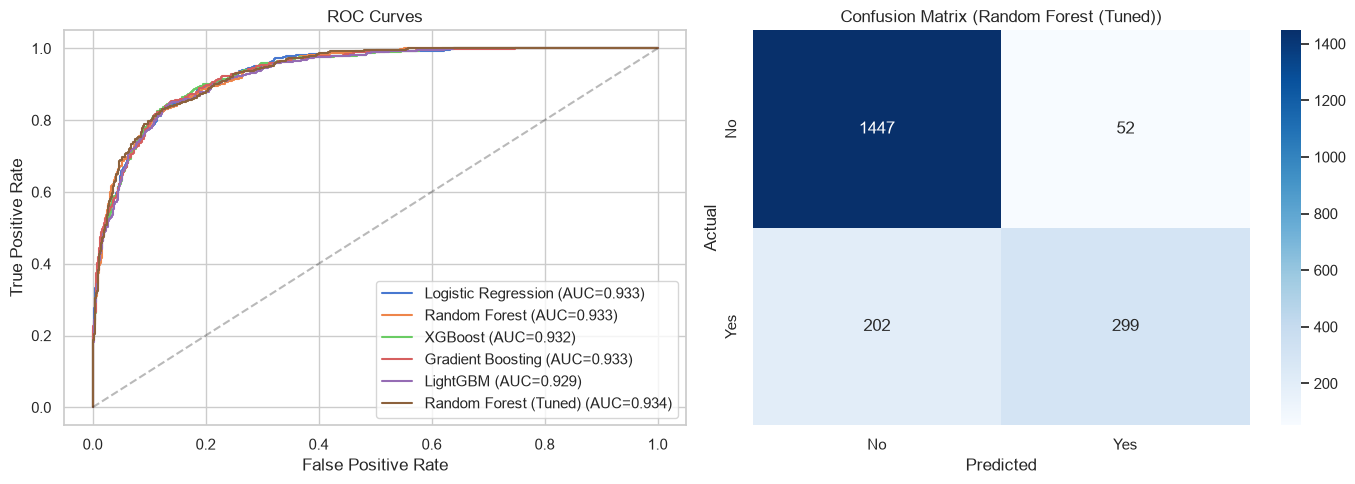


Classification Report (Random Forest (Tuned)):
              precision    recall  f1-score   support

  Low Demand       0.88      0.97      0.92      1499
 High Demand       0.85      0.60      0.70       501

    accuracy                           0.87      2000
   macro avg       0.86      0.78      0.81      2000
weighted avg       0.87      0.87      0.86      2000



In [68]:
all_cls_models = [
    ("Logistic Regression", lr_proba),
    ("Random Forest", rf_proba),
    ("XGBoost", xgb_proba),
    ("Gradient Boosting", gb_proba),
    ("LightGBM", lgbm_proba),
    (f"{best_cls_name} (Tuned)", tuned_cls_proba),
]

final_best_name, final_best_proba = max(all_cls_models, key=lambda x: roc_auc_score(y_test, x[1]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, proba in all_cls_models:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves")
axes[0].legend()

best_pred = (final_best_proba >= 0.5).astype(int)
cm = confusion_matrix(y_test, best_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_title(f"Confusion Matrix ({final_best_name})")

plt.tight_layout()
plt.show()

print(f"\nClassification Report ({final_best_name}):")
print(classification_report(y_test, best_pred, target_names=["Low Demand", "High Demand"]))

### 4.8 Threshold Optimization

The default classification threshold of 0.5 isn't necessarily optimal. We search for the threshold that maximizes F1 score on the validation set, then compare precision/recall trade-offs across thresholds.

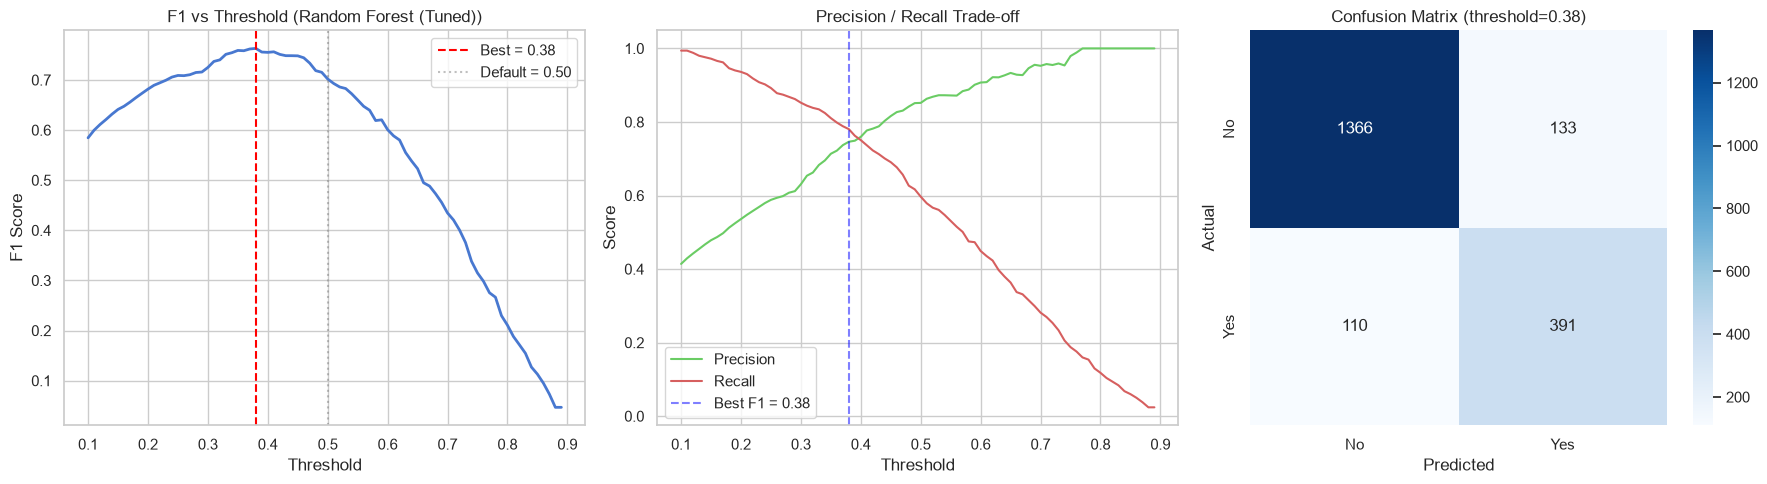

Best model: Random Forest (Tuned)

Metric                Default (0.50) Optimized (0.38)
----------------------------------------------------
Precision                     0.8519         0.7462 (-0.1057)
Recall                        0.5968         0.7804 (+0.1836)
F1                            0.7019         0.7629 (+0.0610)


In [69]:
from sklearn.metrics import precision_score, recall_score, f1_score, precision_recall_curve

thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores = [f1_score(y_test, (final_best_proba >= t).astype(int)) for t in thresholds]
precision_scores = [precision_score(y_test, (final_best_proba >= t).astype(int), zero_division=0) for t in thresholds]
recall_scores = [recall_score(y_test, (final_best_proba >= t).astype(int)) for t in thresholds]

best_threshold = thresholds[np.argmax(f1_scores)]
best_f1 = max(f1_scores)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(thresholds, f1_scores, "b-", linewidth=2)
axes[0].axvline(best_threshold, color="red", linestyle="--", label=f"Best = {best_threshold:.2f}")
axes[0].axvline(0.5, color="gray", linestyle=":", alpha=0.5, label="Default = 0.50")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("F1 Score")
axes[0].set_title(f"F1 vs Threshold ({final_best_name})")
axes[0].legend()

axes[1].plot(thresholds, precision_scores, "g-", label="Precision")
axes[1].plot(thresholds, recall_scores, "r-", label="Recall")
axes[1].axvline(best_threshold, color="blue", linestyle="--", alpha=0.5, label=f"Best F1 = {best_threshold:.2f}")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Score")
axes[1].set_title("Precision / Recall Trade-off")
axes[1].legend()

optimized_pred = (final_best_proba >= best_threshold).astype(int)
cm_opt = confusion_matrix(y_test, optimized_pred)
sns.heatmap(cm_opt, annot=True, fmt="d", cmap="Blues", ax=axes[2],
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Actual")
axes[2].set_title(f"Confusion Matrix (threshold={best_threshold:.2f})")

plt.tight_layout()
plt.show()

default_pred = (final_best_proba >= 0.5).astype(int)
print(f"Best model: {final_best_name}")
print(f"\n{'Metric':<20} {'Default (0.50)':>15} {'Optimized (' + f'{best_threshold:.2f})':>15}")
print("-" * 52)
for metric_name, metric_fn in [("Precision", precision_score), ("Recall", recall_score), ("F1", f1_score)]:
    d = metric_fn(y_test, default_pred)
    o = metric_fn(y_test, optimized_pred)
    change = "+" if o > d else ""
    print(f"{metric_name:<20} {d:>15.4f} {o:>14.4f} ({change}{o - d:.4f})")

### 4.9 Feature Importance (Classification)

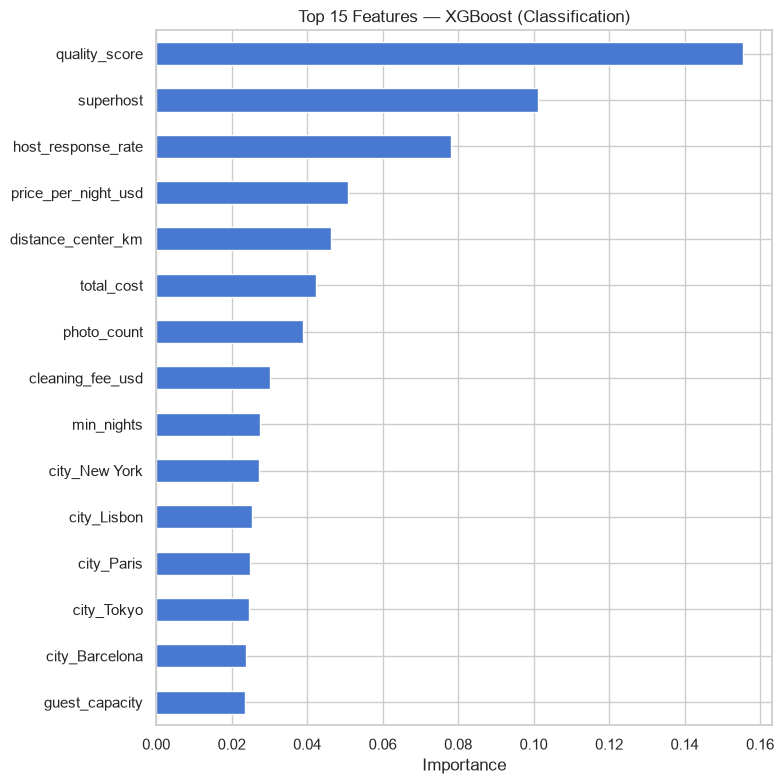

In [70]:
ohe_names = lr_pipe.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(ohe_names)

importances = xgb_pipe.named_steps["clf"].feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 8))
feat_imp.tail(15).plot.barh(ax=ax)
ax.set_title("Top 15 Features — XGBoost (Classification)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## 5. Regression — Predicting Annual Revenue

In [71]:
y_reg = np.log1p(df["annual_revenue_usd"])

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=SEED
)
print(f"Train: {X_train_r.shape}, Test: {X_test_r.shape}")

Train: (8000, 18), Test: (2000, 18)


### 5.1 Ridge Regression (Baseline)

In [72]:
ridge_pipe = Pipeline([
    ("prep", preprocessor),
    ("reg", Ridge(alpha=1.0))
])

ridge_cv = cross_val_score(ridge_pipe, X_train_r, y_train_r, cv=5, scoring="r2")
print(f"Ridge CV R²: {ridge_cv.mean():.4f} ± {ridge_cv.std():.4f}")

ridge_pipe.fit(X_train_r, y_train_r)
ridge_pred = ridge_pipe.predict(X_test_r)

Ridge CV R²: 0.7449 ± 0.0094


### 5.2 Random Forest Regressor

In [73]:
rf_reg_pipe = Pipeline([
    ("prep", preprocessor),
    ("reg", RandomForestRegressor(n_estimators=300, max_depth=12, random_state=SEED, n_jobs=-1))
])

rf_reg_cv = cross_val_score(rf_reg_pipe, X_train_r, y_train_r, cv=5, scoring="r2")
print(f"Random Forest CV R²: {rf_reg_cv.mean():.4f} ± {rf_reg_cv.std():.4f}")

rf_reg_pipe.fit(X_train_r, y_train_r)
rf_reg_pred = rf_reg_pipe.predict(X_test_r)

Random Forest CV R²: 0.7783 ± 0.0166


### 5.3 XGBoost Regressor

In [74]:
xgb_reg_pipe = Pipeline([
    ("prep", preprocessor),
    ("reg", XGBRegressor(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        random_state=SEED, n_jobs=-1
    ))
])

xgb_reg_cv = cross_val_score(xgb_reg_pipe, X_train_r, y_train_r, cv=5, scoring="r2")
print(f"XGBoost CV R²: {xgb_reg_cv.mean():.4f} ± {xgb_reg_cv.std():.4f}")

xgb_reg_pipe.fit(X_train_r, y_train_r)
xgb_reg_pred = xgb_reg_pipe.predict(X_test_r)

XGBoost CV R²: 0.7858 ± 0.0159


### 5.4 Gradient Boosting Regressor

In [75]:
gb_reg_pipe = Pipeline([
    ("prep", preprocessor),
    ("reg", GradientBoostingRegressor(
        n_estimators=300, max_depth=5, learning_rate=0.1, random_state=SEED
    ))
])

gb_reg_cv = cross_val_score(gb_reg_pipe, X_train_r, y_train_r, cv=5, scoring="r2")
print(f"Gradient Boosting CV R²: {gb_reg_cv.mean():.4f} ± {gb_reg_cv.std():.4f}")

gb_reg_pipe.fit(X_train_r, y_train_r)
gb_reg_pred = gb_reg_pipe.predict(X_test_r)

Gradient Boosting CV R²: 0.7885 ± 0.0125


### 5.5 LightGBM Regressor

In [76]:
lgbm_reg_pipe = Pipeline([
    ("prep", preprocessor),
    ("reg", LGBMRegressor(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        random_state=SEED, n_jobs=-1, verbose=-1
    ))
])

lgbm_reg_cv = cross_val_score(lgbm_reg_pipe, X_train_r, y_train_r, cv=5, scoring="r2")
print(f"LightGBM CV R²: {lgbm_reg_cv.mean():.4f} ± {lgbm_reg_cv.std():.4f}")

lgbm_reg_pipe.fit(X_train_r, y_train_r)
lgbm_reg_pred = lgbm_reg_pipe.predict(X_test_r)

LightGBM CV R²: 0.7870 ± 0.0126


### 5.6 Baseline Model Comparison

In [77]:
def reg_metrics(y_true, y_pred, name):
    actual_usd = np.expm1(y_true)
    pred_usd = np.expm1(y_pred)
    return {
        "Model": name,
        "R² (log)": r2_score(y_true, y_pred),
        "RMSE (USD)": np.sqrt(mean_squared_error(actual_usd, pred_usd)),
        "MAE (USD)": mean_absolute_error(actual_usd, pred_usd),
    }

baseline_reg = {
    "Ridge": (ridge_pipe, ridge_pred),
    "Random Forest": (rf_reg_pipe, rf_reg_pred),
    "XGBoost": (xgb_reg_pipe, xgb_reg_pred),
    "Gradient Boosting": (gb_reg_pipe, gb_reg_pred),
    "LightGBM": (lgbm_reg_pipe, lgbm_reg_pred),
}

results_reg_baseline = pd.DataFrame([
    reg_metrics(y_test_r, v[1], k) for k, v in baseline_reg.items()
]).round(2)

results_reg_baseline.sort_values("R² (log)", ascending=False)

,Model,R² (log),RMSE (USD),MAE (USD)
2,XGBoost,0.78,3732.16,2683.00
3,Gradient Boosting,0.78,3724.23,2663.93
4,LightGBM,0.78,3773.65,2684.61
1,Random Forest,0.77,3800.93,2761.27
0,Ridge,0.75,5506.94,3271.69


### 5.7 Hyperparameter Tuning (Best Baseline)

In [78]:
best_reg_name = results_reg_baseline.sort_values("R² (log)", ascending=False).iloc[0]["Model"]
best_reg_pipe = baseline_reg[best_reg_name][0]
print(f"Best baseline: {best_reg_name}")

reg_param_grids = {
    "Ridge": {
        "reg__alpha": [0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0],
    },
    "Random Forest": {
        "reg__n_estimators": [100, 200, 300, 500],
        "reg__max_depth": [6, 8, 10, 12, 15, None],
        "reg__min_samples_split": [2, 5, 10],
        "reg__min_samples_leaf": [1, 2, 4],
        "reg__max_features": ["sqrt", "log2", None],
    },
    "XGBoost": {
        "reg__n_estimators": [100, 200, 300, 500],
        "reg__max_depth": [3, 4, 5, 6, 8],
        "reg__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "reg__subsample": [0.7, 0.8, 0.9, 1.0],
        "reg__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
        "reg__min_child_weight": [1, 3, 5, 7],
        "reg__reg_alpha": [0, 0.01, 0.1, 1.0],
        "reg__reg_lambda": [0.5, 1.0, 2.0, 5.0],
    },
    "Gradient Boosting": {
        "reg__n_estimators": [100, 200, 300, 500],
        "reg__max_depth": [3, 4, 5, 6, 8],
        "reg__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "reg__subsample": [0.7, 0.8, 0.9, 1.0],
        "reg__min_samples_split": [2, 5, 10],
        "reg__min_samples_leaf": [1, 2, 4],
    },
    "LightGBM": {
        "reg__n_estimators": [100, 200, 300, 500],
        "reg__max_depth": [3, 4, 5, 6, 8, -1],
        "reg__learning_rate": [0.01, 0.05, 0.1, 0.2],
        "reg__subsample": [0.7, 0.8, 0.9, 1.0],
        "reg__colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
        "reg__num_leaves": [15, 31, 50, 70, 100],
        "reg__min_child_samples": [5, 10, 20, 30],
        "reg__reg_alpha": [0, 0.01, 0.1, 1.0],
        "reg__reg_lambda": [0, 0.01, 0.1, 1.0],
    },
}

reg_search = RandomizedSearchCV(
    best_reg_pipe, reg_param_grids[best_reg_name], n_iter=50, cv=5, scoring="r2",
    random_state=SEED, n_jobs=-1, verbose=1
)
reg_search.fit(X_train_r, y_train_r)

print(f"\nBest CV R²: {reg_search.best_score_:.4f}")
print(f"Best params: {reg_search.best_params_}")

tuned_reg_pred = reg_search.predict(X_test_r)
print(f"Tuned {best_reg_name} Test R²: {r2_score(y_test_r, tuned_reg_pred):.4f}")

Best baseline: XGBoost
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best CV R²: 0.8027
Best params: {'reg__subsample': 0.8, 'reg__reg_lambda': 2.0, 'reg__reg_alpha': 1.0, 'reg__n_estimators': 200, 'reg__min_child_weight': 1, 'reg__max_depth': 4, 'reg__learning_rate': 0.05, 'reg__colsample_bytree': 0.6}
Tuned XGBoost Test R²: 0.7958


### 5.8 Final Regression Comparison

In [79]:
results_reg_final = pd.DataFrame([
    reg_metrics(y_test_r, ridge_pred, "Ridge"),
    reg_metrics(y_test_r, rf_reg_pred, "Random Forest"),
    reg_metrics(y_test_r, xgb_reg_pred, "XGBoost"),
    reg_metrics(y_test_r, gb_reg_pred, "Gradient Boosting"),
    reg_metrics(y_test_r, lgbm_reg_pred, "LightGBM"),
    reg_metrics(y_test_r, tuned_reg_pred, f"{best_reg_name} (Tuned)"),
]).round(2)

results_reg_final.sort_values("R² (log)", ascending=False)

,Model,R² (log),RMSE (USD),MAE (USD)
5,XGBoost (Tuned),0.80,3624.43,2588.14
2,XGBoost,0.78,3732.16,2683.00
3,Gradient Boosting,0.78,3724.23,2663.93
4,LightGBM,0.78,3773.65,2684.61
1,Random Forest,0.77,3800.93,2761.27
0,Ridge,0.75,5506.94,3271.69


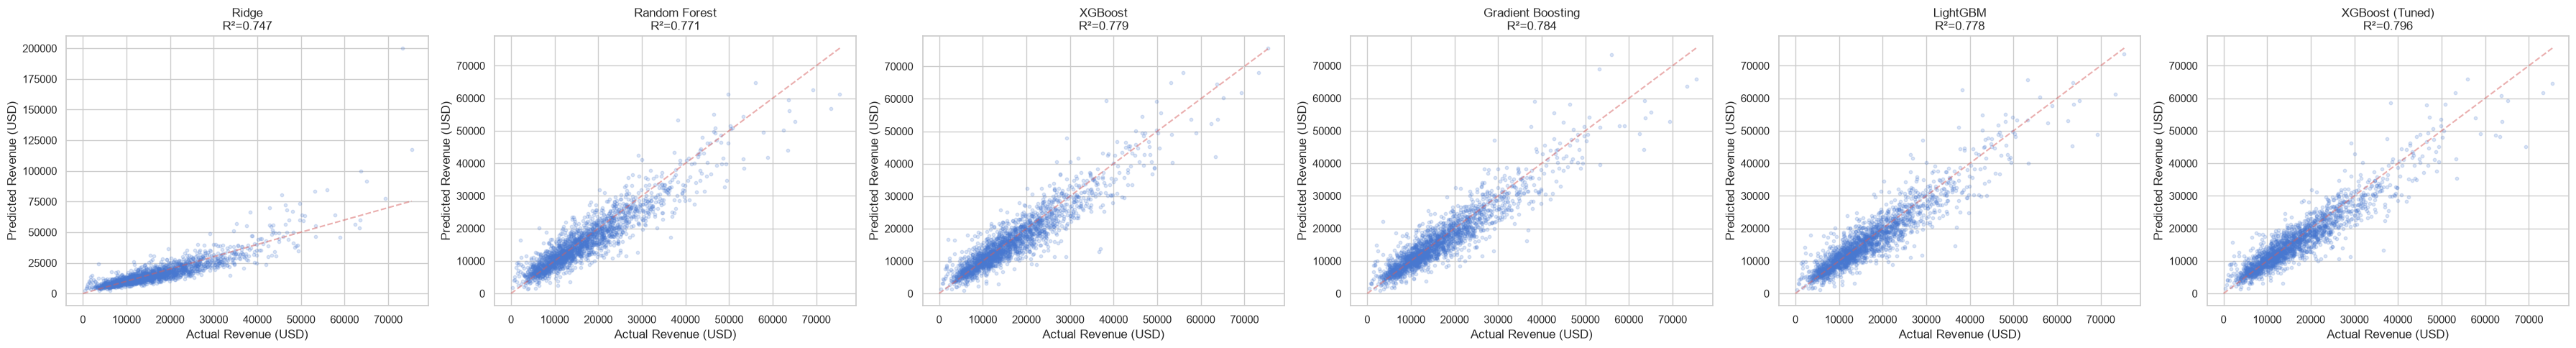

In [80]:
all_reg_preds = [
    (ridge_pred, "Ridge"),
    (rf_reg_pred, "Random Forest"),
    (xgb_reg_pred, "XGBoost"),
    (gb_reg_pred, "Gradient Boosting"),
    (lgbm_reg_pred, "LightGBM"),
    (tuned_reg_pred, f"{best_reg_name} (Tuned)"),
]

fig, axes = plt.subplots(1, len(all_reg_preds), figsize=(6 * len(all_reg_preds), 5))

for ax, (pred, name) in zip(axes, all_reg_preds):
    actual_usd = np.expm1(y_test_r)
    pred_usd = np.expm1(pred)
    ax.scatter(actual_usd, pred_usd, alpha=0.2, s=10)
    lims = [0, actual_usd.max()]
    ax.plot(lims, lims, "r--", alpha=0.5)
    ax.set_xlabel("Actual Revenue (USD)")
    ax.set_ylabel("Predicted Revenue (USD)")
    ax.set_title(f"{name}\nR²={r2_score(y_test_r, pred):.3f}")

plt.tight_layout()
plt.show()

### 5.9 Feature Importance (Regression)

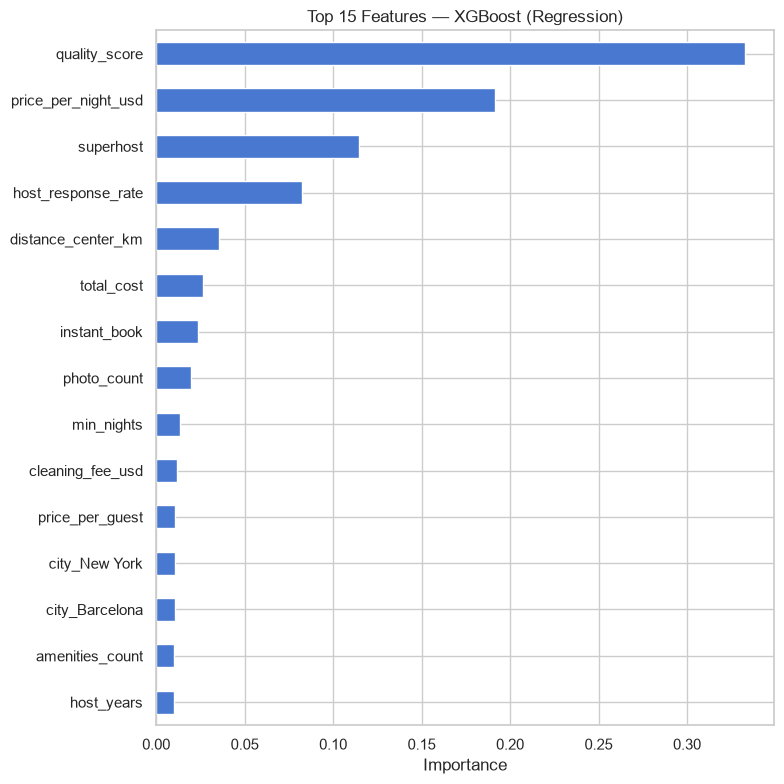

In [81]:
importances_reg = xgb_reg_pipe.named_steps["reg"].feature_importances_
feat_imp_reg = pd.Series(importances_reg, index=all_feature_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 8))
feat_imp_reg.tail(15).plot.barh(ax=ax)
ax.set_title("Top 15 Features — XGBoost (Regression)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## 6. Key Findings

### Classification (High Demand)
- **Best model:** Random Forest (Tuned) — Test AUC 0.9342, narrowly beating Logistic Regression (0.9327) and Gradient Boosting (0.9327)
- All five models performed within ~0.005 AUC of each other, indicating the signal is learnable even with a linear model
- **Threshold optimization** (0.50 → 0.38) boosted F1 from 0.70 to 0.76 by trading a small precision drop (0.85 → 0.75) for a large recall gain (0.60 → 0.78)
- Multicollinearity analysis confirmed `quality_score = photo_count + amenities_count` creates perfect redundancy (VIF ~10¹⁵), but tree models handle this natively without accuracy loss

### Regression (Annual Revenue)
- **Best model:** XGBoost (Tuned) — Test R² 0.796, RMSE ~\$3,700, MAE ~\$2,680
- Log-transforming revenue (`np.log1p`) was critical due to right-skewed distribution (skewness = 1.65)
- Ensemble methods substantially outperform Ridge (R² 0.75, RMSE ~\$5,500), capturing nonlinear pricing dynamics

### Feature Engineering & Interactions
- Only 1 of 14 candidate interactions provided meaningful AUC lift: `price_per_night_usd × distance_center_km` (+0.00118), confirming tree models already discover most interactions internally
- Engineered features (`total_cost`, `price_per_guest`, `quality_score`) added domain knowledge but introduced expected collinearity with their source features

### Business Insights
- **City matters:** Bangkok and Cape Town have the highest demand rates (~40%) despite the lowest average prices (~\$61–64/night) — affordability drives occupancy
- **Price–location interaction:** the only beneficial interaction feature was price × distance-to-center, suggesting central listings can sustain higher prices without hurting demand
- **Revenue ≠ demand:** London and New York lead in revenue (~\$18K/yr) but have the lowest demand rates (~20%) — high prices compensate for lower occupancy